Question 1: Comparing Removal and Capping in Employee Data

A. Detect outliers, removal and capping

In [4]:

import pandas as pd
import numpy as np

df = pd.DataFrame({
    "Employee_ID": range(1, 11),
    "Age": [22, 25, 28, 30, 32, 35, 38, 40, 42, 100],
    "Salary": [25000, 28000, 30000, 32000, 35000,
               38000, 42000, 45000, 50000, 500000]
})

print(df)


   Employee_ID  Age  Salary
0            1   22   25000
1            2   25   28000
2            3   28   30000
3            4   30   32000
4            5   32   35000
5            6   35   38000
6            7   38   42000
7            8   40   45000
8            9   42   50000
9           10  100  500000


B. Compare original, removed and capped datasets

Age Lower: 12.0 Upper: 56.0
Salary Lower: 9875.0 Upper: 64875.0

 Original Rows: 10
          Age     Salary
mean    39.20   82500.00
median  33.50   36500.00
std     22.32  146904.54

 Removed Rows: 9
          Age    Salary
mean    32.44  36111.11
median  32.00  35000.00
std      6.86   8328.33

 Capped Rows: 10
          Age    Salary
mean    34.80  38987.50
median  33.50  36500.00
std      9.86  12016.26


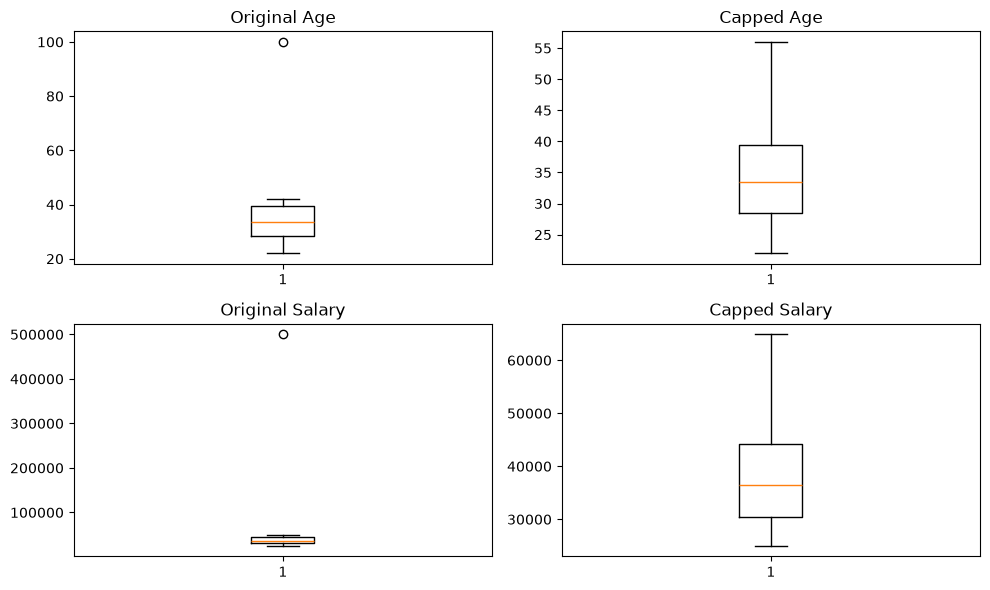

In [6]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Employee_ID": range(1, 11),
    "Age": [22,25,28,30,32,35,38,40,42,100],
    "Salary": [25000,28000,30000,32000,35000,
               38000,42000,45000,50000,500000]
})

# IQR and outlier detection
flags = pd.DataFrame(index=df.index)
capped = df.copy()

for col in ["Age", "Salary"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr

    flags[col] = (df[col] < low) | (df[col] > high)
    capped[col] = df[col].clip(low, high)

    print(col, "Lower:", low, "Upper:", high)

# Remove outlier rows
removed = df[~flags.any(axis=1)].copy()

# Compare datasets
datasets = {
    "Original": df,
    "Removed": removed,
    "Capped": capped
}

for name, data in datasets.items():
    print("\n", name, "Rows:", len(data))
    print(data[["Age", "Salary"]].agg(
        ["mean", "median", "std"]
    ).round(2))

# Boxplots
fig, axes = plt.subplots(2, 2, figsize=(10, 6))

axes[0,0].boxplot(df["Age"])
axes[0,0].set_title("Original Age")

axes[0,1].boxplot(capped["Age"])
axes[0,1].set_title("Capped Age")

axes[1,0].boxplot(df["Salary"])
axes[1,0].set_title("Original Salary")

axes[1,1].boxplot(capped["Salary"])
axes[1,1].set_title("Capped Salary")

plt.tight_layout()
plt.show()


Question 2: Outlier Handling in Retail Sales

A. Apply IQR-based removal and capping

Sales Q1: 1475.0 Q3: 1950.0
IQR: 475.0 Lower: 762.5 Upper: 2662.5
Customers Q1: 34.5 Q3: 47.75
IQR: 13.25 Lower: 14.625 Upper: 67.625

Outlier Records:
    Day  Sales  Customers
11   12  25000        500

Removed Days: [12]
Rows after removal: 11

Capped Values:
    Day   Sales  Customers
11   12  2662.5     67.625


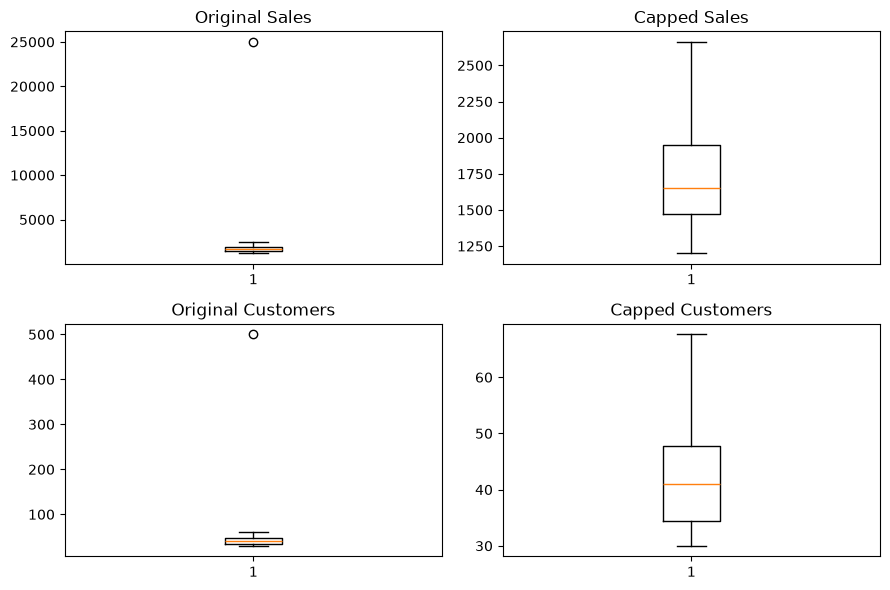

In [7]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Day": range(1, 13),
    "Sales": [1200,1350,1400,1500,1600,1550,
              1700,1800,1900,2100,2500,25000],
    "Customers": [30,32,35,33,38,40,42,45,47,50,60,500]
})

flags = pd.DataFrame(index=df.index)
capped = df.copy()

for col in ["Sales", "Customers"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr

    flags[col] = (df[col] < low) | (df[col] > high)
    capped[col] = df[col].clip(low, high)

    print(col, "Q1:", q1, "Q3:", q3)
    print("IQR:", iqr, "Lower:", low, "Upper:", high)

print("\nOutlier Records:")
print(df[flags.any(axis=1)])

# Removed dataset
removed = df[~flags.any(axis=1)].copy()

print("\nRemoved Days:", df.loc[flags.any(axis=1), "Day"].tolist())
print("Rows after removal:", len(removed))

print("\nCapped Values:")
print(capped[capped["Day"] == 12])

# Boxplots
fig, ax = plt.subplots(2, 2, figsize=(9, 6))

ax[0,0].boxplot(df["Sales"])
ax[0,0].set_title("Original Sales")

ax[0,1].boxplot(capped["Sales"])
ax[0,1].set_title("Capped Sales")

ax[1,0].boxplot(df["Customers"])
ax[1,0].set_title("Original Customers")

ax[1,1].boxplot(capped["Customers"])
ax[1,1].set_title("Capped Customers")

plt.tight_layout()
plt.show()


B. Compare correlation before and after handling outliers

In [8]:

# Correlation comparison
print("Original Correlation:",
      round(df["Sales"].corr(df["Customers"]), 4))

print("Removed Correlation:",
      round(removed["Sales"].corr(removed["Customers"]), 4))

print("Capped Correlation:",
      round(capped["Sales"].corr(capped["Customers"]), 4))


Original Correlation: 0.9999
Removed Correlation: 0.9847
Capped Correlation: 0.9892


Question 3: Handling Outliers Without Losing Customer Records

A. Detect outliers using the IQR method

In [9]:

import pandas as pd

df = pd.DataFrame({
    "Customer_ID": range(101, 113),
    "Annual_Spending": [8000,10000,12000,15000,18000,20000,22000,25000,30000,35000,50000,800000],
    "Order_Count": [2,3,3,4,5,5,6,7,8,9,12,100],
    "Customer_Segment": ["Basic","Basic","Silver","Silver",
                         "Gold","Basic","Silver","Gold",
                         "Gold","Silver","Premium","Premium"]
})

flags = pd.DataFrame(index=df.index)
capped = df.copy()

for col in ["Annual_Spending", "Order_Count"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr

    flags[col] = (df[col] < low) | (df[col] > high)
    capped[col] = df[col].clip(low, high)

    print(col, "Q1:", q1, "Q3:", q3)
    print("IQR:", iqr, "Lower:", low, "Upper:", high)

# Removal dataset
removed = df[~flags.any(axis=1)].copy()

# Display outlier records
print("\nOutlier Records:")
print(df[flags.any(axis=1)])

# Display capped data
print("\nCapped Dataset:")
print(capped)

print("\nOriginal Rows:", len(df))
print("Removed Rows:", len(removed))
print("Capped Rows:", len(capped))
print("All customers retained:", len(capped) == len(df))


Annual_Spending Q1: 14250.0 Q3: 31250.0
IQR: 17000.0 Lower: -11250.0 Upper: 56750.0
Order_Count Q1: 3.75 Q3: 8.25
IQR: 4.5 Lower: -3.0 Upper: 15.0

Outlier Records:
    Customer_ID  Annual_Spending  Order_Count Customer_Segment
11          112           800000          100          Premium

Capped Dataset:
    Customer_ID  Annual_Spending  Order_Count Customer_Segment
0           101             8000            2            Basic
1           102            10000            3            Basic
2           103            12000            3           Silver
3           104            15000            4           Silver
4           105            18000            5             Gold
5           106            20000            5            Basic
6           107            22000            6           Silver
7           108            25000            7             Gold
8           109            30000            8             Gold
9           110            35000            9           Silver

B. Compare customer segments and spending statistics

In [10]:

# Customer segment comparison
print("Original Segment Counts:")
print(df["Customer_Segment"].value_counts().sort_index())

print("\nAfter Removal:")
print(removed["Customer_Segment"].value_counts().sort_index())

print("\nAfter Capping:")
print(capped["Customer_Segment"].value_counts().sort_index())

# Spending statistics
for name, data in {
    "Original": df,
    "Removed": removed,
    "Capped": capped
}.items():
    print("\n", name)
    print("Mean:", round(data["Annual_Spending"].mean(), 2))
    print("Median:", data["Annual_Spending"].median())


Original Segment Counts:
Customer_Segment
Basic      3
Gold       3
Premium    2
Silver     4
Name: count, dtype: int64

After Removal:
Customer_Segment
Basic      3
Gold       3
Premium    1
Silver     4
Name: count, dtype: int64

After Capping:
Customer_Segment
Basic      3
Gold       3
Premium    2
Silver     4
Name: count, dtype: int64

 Original
Mean: 87083.33
Median: 21000.0

 Removed
Mean: 22272.73
Median: 20000.0

 Capped
Mean: 25145.83
Median: 21000.0


Question 4: Building a Reusable Outlier Treatment Function

A. Create a reusable function using IQR

In [13]:

import pandas as pd

df = pd.DataFrame({
    "Product": ["A","B","C","D","E","F","G","H"],
    "Price": [100,120,130,140,150,170,200,2000],
    "Delivery_Days": [1,2,2,3,3,4,5,40],
    "Rating": [3.5,4.0,4.2,4.5,4.1,3.8,4.6,1.0]})

def treat_outliers(df, columns, method="remove"):
    if method not in ["remove", "cap"]:
        raise ValueError("Method must be remove or cap")

    if not set(columns).issubset(df.columns):
        raise ValueError("Invalid column name")

    if not all(pd.api.types.is_numeric_dtype(df[c])
               for c in columns):
        raise TypeError("Selected columns must be numeric")

    data = df.copy()
    report = []
    flags = pd.DataFrame(False, index=df.index,
                         columns=columns)

    for col in columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        low = q1 - 1.5 * iqr
        high = q3 + 1.5 * iqr

        flags[col] = (df[col] < low) | (df[col] > high)

        report.append({
            "Column": col,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Lower": low,
            "Upper": high,
            "Outliers": int(flags[col].sum())
        })

        if method == "cap":
            data[col] = data[col].clip(low, high)

    if method == "remove":
        data = data.loc[~flags.any(axis=1)].copy()

    return data, pd.DataFrame(report)


B. Apply both methods and compare results

In [14]:

cols = ["Price", "Delivery_Days", "Rating"]

# Removal
removed, report1 = treat_outliers(df, cols, "remove")

# Capping
capped, report2 = treat_outliers(df, cols, "cap")

print("IQR Report:")
print(report1.round(2))

print("\nOriginal Rows:", len(df))
print("Removed Rows:", len(removed))
print("Capped Rows:", len(capped))

print("\nOriginal Statistics:")
print(df[cols].agg(["mean","median","std"]).round(2))

print("\nRemoved Statistics:")
print(removed[cols].agg(["mean","median","std"]).round(2))

print("\nCapped Statistics:")
print(capped[cols].agg(["mean","median","std"]).round(2))

print("\nOriginal Data Unchanged:")
print(df)


IQR Report:
          Column      Q1      Q3    IQR  Lower   Upper  Outliers
0          Price  127.50  177.50  50.00  52.50  252.50         1
1  Delivery_Days    2.00    4.25   2.25  -1.38    7.62         1
2         Rating    3.72    4.28   0.55   2.90    5.10         1

Original Rows: 8
Removed Rows: 7
Capped Rows: 8

Original Statistics:
         Price  Delivery_Days  Rating
mean    376.25           7.50    3.71
median  145.00           3.00    4.05
std     656.81          13.19    1.15

Removed Statistics:
         Price  Delivery_Days  Rating
mean    144.29           2.86    4.10
median  140.00           3.00    4.10
std      33.09           1.35    0.38

Capped Statistics:
         Price  Delivery_Days  Rating
mean    157.81           3.45    3.95
median  145.00           3.00    4.05
std      49.02           2.10    0.55

Original Data Unchanged:
  Product  Price  Delivery_Days  Rating
0       A    100              1     3.5
1       B    120              2     4.0
2       C    1